# Complete FD001 training workflow

This root notebook is the one-command alternative to running stage notebooks 01-05. It calls the maintained package pipeline, rather than defining a second set of models, features or artifact formats.

Install `uv sync --locked --extra notebooks`, select the project Python kernel, then **Restart Kernel and Run All Cells**. The bundled source data is sufficient; no Parquet files or generated artifacts are required beforehand.

For an optional LSTM experiment, also install the `deep-learning` extra and change `TRAIN_LSTM` below. Test scores do not determine the classical serving champion.


In [1]:
from pathlib import Path
import os
import sys

ROOT = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "pyproject.toml").is_file()
     and (path / "src" / "predictive_maintenance").is_dir()),
    None,
)
if ROOT is None:
    raise RuntimeError("Open this notebook from the project root or its notebooks directory.")
sys.path.insert(0, str(ROOT / "src"))
os.environ.setdefault("PM_PROJECT_ROOT", str(ROOT))

import numpy as np
import pandas as pd
from IPython.display import display
from loguru import logger
from predictive_maintenance.config import (
    EXTERNAL_DATA_DIR, RAW_DATA_DIR, INTERIM_DATA_DIR,
    PROCESSED_DATA_DIR, MODELS_DIR, RESULTS_DIR, FIGURES_DIR,
    RUL_CAP, TREND_WINDOW, SETTINGS,
)

logger.remove()
logger.add(sys.stderr, level="WARNING")
pd.set_option("display.max_columns", 40)
print(f"Project: {ROOT.name} | Python: {sys.version.split()[0]}")


Project: Predictive-Maintenance-for-Sensor-Data | Python: 3.13.9


In [2]:
import matplotlib.pyplot as plt
import seaborn as sns
from IPython import get_ipython

get_ipython().run_line_magic("matplotlib", "inline")
sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.figsize": (10, 4), "figure.dpi": 100})
FIGURES_DIR.mkdir(parents=True, exist_ok=True)


## Run ingestion, preprocessing, feature engineering, training and evaluation


In [3]:
from predictive_maintenance.pipeline import main as run_pipeline

TRAIN_LSTM = False
N_SPLITS = SETTINGS.get("n_splits", 5)
run_pipeline(n_splits=N_SPLITS, train_lstm=TRAIN_LSTM)


## Review validation and held-out test results


In [4]:
import json

comparison = pd.read_csv(RESULTS_DIR / "model_comparison.csv")
manifest = json.loads((MODELS_DIR / "best_model.json").read_text())
display(comparison.sort_values("RMSE_mean"))
display(pd.read_csv(RESULTS_DIR / "test_evaluation.csv"))
display(pd.read_csv(RESULTS_DIR / "evaluation.csv"))
print("Serving champion:", manifest["model_name"])
assert manifest["selection_metric"] == "groupkfold_RMSE"


,model,MAE_mean,MAE_std,RMSE_mean,RMSE_std
0,LightGBM,12.912403,1.198666,17.825632,1.524688
2,XGBoost,13.029350,1.230391,17.942778,1.547701
1,LinearRegression,16.967198,1.062759,20.920921,1.053402


,model,MAE,RMSE,n_engines
0,LightGBM,11.826881,16.377040,100
1,XGBoost,12.304318,16.527736,100
2,LinearRegression,16.021368,20.254767,100


,MAE,RMSE,R2,PHM08,n_engines
0,11.826881,16.37704,0.832983,607.393744,100


Serving champion: LightGBM


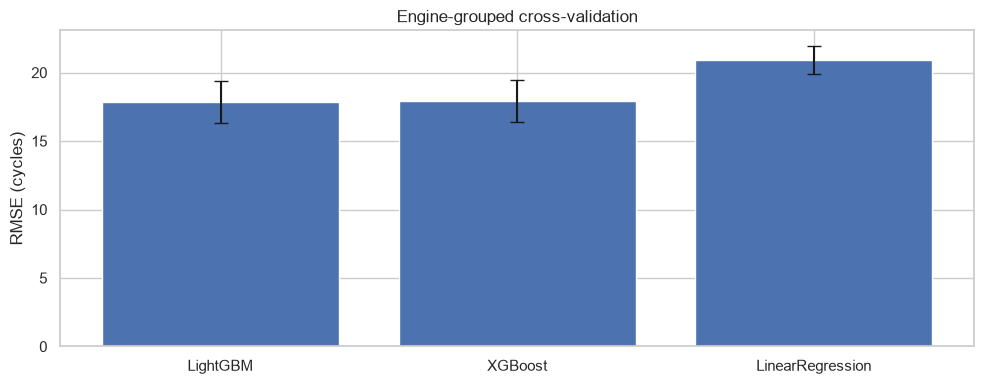

In [5]:
ordered = comparison.sort_values("RMSE_mean")
fig, ax = plt.subplots()
ax.bar(ordered.model, ordered.RMSE_mean, yerr=ordered.RMSE_std, capsize=5)
ax.set(title="Engine-grouped cross-validation", ylabel="RMSE (cycles)")
plt.tight_layout()
plt.show()


## Load the same artifact used by the API


In [6]:
from predictive_maintenance.api.inference import ModelService

service = ModelService(MODELS_DIR)
service.load()
test_raw = pd.read_csv(RAW_DATA_DIR / "test_data.csv")
engine = test_raw.loc[test_raw.unit == test_raw.unit.min()].sort_values("cycle")
readings = engine.drop(columns=["unit", "cycle"]).to_dict("records")
display(pd.Series(service.predict(readings, unit="engine_001"), name="prediction").to_frame())


,prediction
unit,engine_001
predicted_rul,119.17
predicted_class,healthy
model_name,LightGBM
n_readings_received,31
n_readings_used,10
latency_ms,53.1


For detailed sensor analysis use `notebooks/01_eda.ipynb`. For a results report with measured scores and exported figures use `notebooks/EDA_resultats_maintenance_predictive.ipynb`. Start HTTP serving with `uv run python -m uvicorn predictive_maintenance.api.main:app --port 8000`.
